In [3]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd
import tensorflow as tf


# ============================================================
# Repository
# ============================================================

AI_ROOT = Path(
    "/content/drive/MyDrive/TRON/AI"
)

if str(AI_ROOT) not in sys.path:
    sys.path.insert(
        0,
        str(AI_ROOT),
    )


from src.dataset import (
    load_normalization_stats,
    load_split_manifest,
    select_split,
    make_dataset,
)


# ============================================================
# Paths
# ============================================================

DATASET_ROOT = Path(
    "/content/drive/MyDrive/TRON/AI/dataset"
)

CLIP_ROOT = (
    DATASET_ROOT
    / "processed"
    / "clips_16k_1s"
)

AI05_META = (
    DATASET_ROOT
    / "metadata"
    / "05_split_info"
)

SPLIT_MANIFEST = (
    AI05_META
    / "split_manifest.csv"
)

NORMALIZATION_NPZ = (
    AI05_META
    / "normalization_stats.npz"
)


# ============================================================
# Load AI-05 results
# ============================================================

manifest = load_split_manifest(
    SPLIT_MANIFEST
)

mean, std = (
    load_normalization_stats(
        NORMALIZATION_NPZ
    )
)

test_df = select_split(
    manifest,
    "TEST",
)

print(
    "TEST clips:",
    len(test_df)
)

print()
print(
    test_df["class_name"]
    .value_counts()
)


assert len(test_df) == 1162


# ============================================================
# Dataset
# ============================================================

test_ds = make_dataset(
    test_df,
    clip_root=CLIP_ROOT,
    mean=mean,
    std=std,
    training=False,
    batch_size=32,
)

print(
    "TEST dataset created"
)

TEST clips: 1162

class_name
COUGH    768
OTHER    228
SNORE    166
Name: count, dtype: int64
TEST dataset created


In [4]:
assert len(test_df) == 1162

print(
    test_df["class_name"]
    .value_counts()
)

class_name
COUGH    768
OTHER    228
SNORE    166
Name: count, dtype: int64


In [5]:
# reload best model

from tensorflow import keras

BEST_MODEL_PATH = (
    AI_ROOT
    / "model"
    / "baseline_float32.keras"
)

best_model = keras.models.load_model(
    BEST_MODEL_PATH
)

print("Best model loaded")

Best model loaded


In [6]:
best_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 98, 40, 8)      │            72 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 98, 40, 8)      │            32 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu (ReLU)                    │ (None, 98, 40, 8)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 49, 20, 8)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 49, 20, 16)     │         1,152 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 49, 20, 16)     │            64 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_1 (ReLU)                  │ (None, 49, 20, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 24, 10, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 24, 10, 32)     │         4,608 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 24, 10, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_2 (ReLU)                  │ (None, 24, 10, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 32)             │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 3)              │            99 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 18,243 (71.27 KB)

 Trainable params: 6,043 (23.61 KB)

 Non-trainable params: 112 (448.00 B)

 Optimizer params: 12,088 (47.22 KB)

In [7]:
test_loss, test_accuracy = (
    best_model.evaluate(
        test_ds,
        verbose=1,
    )
)

print(
    "TEST loss    :",
    test_loss
)

print(
    "TEST accuracy:",
    test_accuracy
)

37/37 ━━━━━━━━━━━━━━━━━━━━ 367s 10s/step - accuracy: 0.9501 - loss: 0.1400
TEST loss    : 0.1400296539068222
TEST accuracy: 0.9500860571861267


/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


In [8]:
y_prob = best_model.predict(
    test_ds,
    verbose=1,
)

print(
    "Probability shape:",
    y_prob.shape
)

assert y_prob.shape == (
    1162,
    3,
)

assert np.isfinite(
    y_prob
).all()

37/37 ━━━━━━━━━━━━━━━━━━━━ 1s 27ms/step
Probability shape: (1162, 3)


In [9]:
y_pred = np.argmax(
    y_prob,
    axis=1,
).astype(np.int32)

In [10]:
y_true = (
    test_df["class_id"]
    .astype(np.int32)
    .to_numpy()
)

assert y_true.shape == (1162,)
assert y_pred.shape == (1162,)

In [11]:
prediction_accuracy = (
    y_true == y_pred
).mean()

print(
    "Prediction accuracy:",
    prediction_accuracy
)

print(
    "Keras accuracy     :",
    test_accuracy
)

assert np.isclose(
    prediction_accuracy,
    test_accuracy,
    atol=1e-6,
)

print(
    "TEST accuracy consistency check: OK"
)

Prediction accuracy: 0.9500860585197934
Keras accuracy     : 0.9500860571861267
TEST accuracy consistency check: OK


In [12]:
from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
)

CLASS_NAMES = [
    "OTHER",
    "SNORE",
    "COUGH",
]

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=[0, 1, 2],
)

print(cm)

[[204  15   9]
 [ 11 151   4]
 [ 17   2 749]]


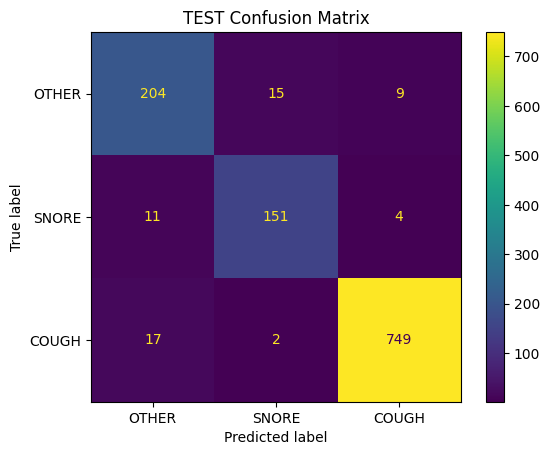

In [13]:
import matplotlib.pyplot as plt

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=CLASS_NAMES,
)

disp.plot(
    values_format="d",
)

plt.title(
    "TEST Confusion Matrix"
)

plt.show()

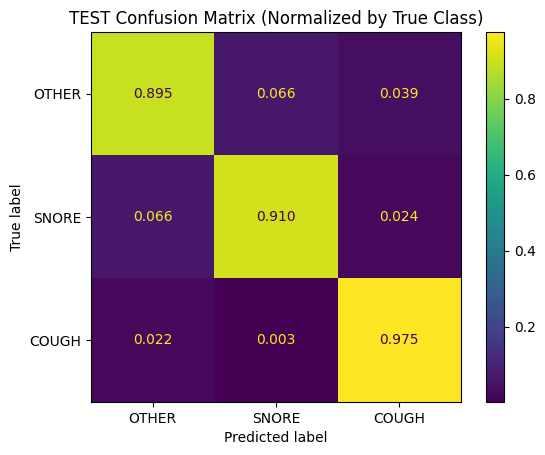

In [14]:
cm_norm = confusion_matrix(
    y_true,
    y_pred,
    labels=[0, 1, 2],
    normalize="true",
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_norm,
    display_labels=CLASS_NAMES,
)

disp.plot(
    values_format=".3f",
)

plt.title(
    "TEST Confusion Matrix "
    "(Normalized by True Class)"
)

plt.show()

In [15]:
from sklearn.metrics import (
    classification_report,
    precision_recall_fscore_support,
    f1_score,
)

report = classification_report(
    y_true,
    y_pred,
    labels=[0, 1, 2],
    target_names=CLASS_NAMES,
    digits=4,
)

print(report)

              precision    recall  f1-score   support

       OTHER     0.8793    0.8947    0.8870       228
       SNORE     0.8988    0.9096    0.9042       166
       COUGH     0.9829    0.9753    0.9791       768

    accuracy                         0.9501      1162
   macro avg     0.9204    0.9265    0.9234      1162
weighted avg     0.9506    0.9501    0.9503      1162



In [16]:
macro_f1 = f1_score(
    y_true,
    y_pred,
    average="macro",
)

print(
    "Macro F1:",
    macro_f1
)

Macro F1: 0.9234110352752863


In [17]:
precision, recall, f1, support = (
    precision_recall_fscore_support(
        y_true,
        y_pred,
        labels=[0, 1, 2],
        zero_division=0,
    )
)

metrics_df = pd.DataFrame({
    "class_id": [0, 1, 2],
    "class_name": CLASS_NAMES,
    "precision": precision,
    "recall": recall,
    "f1": f1,
    "support": support,
})

print(metrics_df)

   class_id class_name  precision    recall        f1  support
0         0      OTHER    0.87931  0.894737  0.886957      228
1         1      SNORE    0.89881  0.909639  0.904192      166
2         2      COUGH    0.98294  0.975260  0.979085      768


In [18]:
prediction_df = test_df.copy()

prediction_df[
    "predicted_class_id"
] = y_pred

prediction_df[
    "predicted_class_name"
] = [
    CLASS_NAMES[i]
    for i in y_pred
]

prediction_df[
    "confidence"
] = y_prob.max(
    axis=1
)

prediction_df[
    "prob_other"
] = y_prob[:, 0]

prediction_df[
    "prob_snore"
] = y_prob[:, 1]

prediction_df[
    "prob_cough"
] = y_prob[:, 2]

prediction_df[
    "correct"
] = (
    y_true == y_pred
)

In [19]:
print(
    prediction_df["correct"]
    .value_counts()
)

correct
True     1104
False      58
Name: count, dtype: int64


In [20]:
errors = (
    prediction_df[
        ~prediction_df["correct"]
    ]
    .copy()
)

print(
    "Misclassified:",
    len(errors)
)

Misclassified: 58


In [21]:
print(
    errors[
        [
            "clip_id",
            "source_dataset",
            "class_name",
            "predicted_class_name",
            "confidence",
        ]
    ]
    .sort_values(
        "confidence",
        ascending=False,
    )
    .head(30)
    .to_string(index=False)
)

                                                     clip_id  source_dataset class_name predicted_class_name  confidence
                                        esc50__3-216284-A-39          ESC-50      OTHER                COUGH    0.981964
              audioset__audioset_HCXAVkq1ces_80000_event_001 AudioSet Strong      SNORE                OTHER    0.971351
                                        esc50__3-147342-A-34          ESC-50      OTHER                COUGH    0.965138
coswara__20200707_fAJb4UlkROgJdxoF8hKZao5rrmt1_cough-shallow         Coswara      COUGH                OTHER    0.962942
                                        esc50__4-223125-A-14          ESC-50      OTHER                SNORE    0.955645
                                        esc50__3-147965-A-12          ESC-50      OTHER                SNORE    0.949683
coswara__20210714_sgYoFXPJ01ekO1Fa1ePU5OsiWda2_cough-shallow         Coswara      COUGH                OTHER    0.947284
                                

In [22]:
dataset_eval = (
    prediction_df
    .groupby(
        "source_dataset"
    )
    .agg(
        samples=(
            "correct",
            "size",
        ),
        correct=(
            "correct",
            "sum",
        ),
        accuracy=(
            "correct",
            "mean",
        ),
    )
    .reset_index()
)

print(dataset_eval)

    source_dataset  samples  correct  accuracy
0  AudioSet Strong      160      145  0.906250
1          Coswara      762      743  0.975066
2           ESC-50      240      216  0.900000


In [23]:
stratum_eval = (
    prediction_df
    .groupby(
        [
            "source_dataset",
            "class_name",
        ]
    )
    .agg(
        samples=(
            "correct",
            "size",
        ),
        correct=(
            "correct",
            "sum",
        ),
        accuracy=(
            "correct",
            "mean",
        ),
    )
    .reset_index()
)

print(stratum_eval)

    source_dataset class_name  samples  correct  accuracy
0  AudioSet Strong      SNORE      160      145  0.906250
1          Coswara      COUGH      762      743  0.975066
2           ESC-50      COUGH        6        6  1.000000
3           ESC-50      OTHER      228      204  0.894737
4           ESC-50      SNORE        6        6  1.000000


In [24]:
AI07_META = (
    DATASET_ROOT
    / "metadata"
    / "07_evaluation_info"
)

AI07_META.mkdir(
    parents=True,
    exist_ok=True,
)

metrics_df.to_csv(
    AI07_META
    / "classification_metrics.csv",
    index=False,
)

pd.DataFrame(
    cm,
    index=CLASS_NAMES,
    columns=CLASS_NAMES,
).to_csv(
    AI07_META
    / "confusion_matrix.csv"
)

prediction_df.to_csv(
    AI07_META
    / "test_predictions.csv",
    index=False,
)

dataset_eval.to_csv(
    AI07_META
    / "dataset_metrics.csv",
    index=False,
)

stratum_eval.to_csv(
    AI07_META
    / "stratum_metrics.csv",
    index=False,
)

In [25]:
print(dataset_eval)
print()
print(stratum_eval)

    source_dataset  samples  correct  accuracy
0  AudioSet Strong      160      145  0.906250
1          Coswara      762      743  0.975066
2           ESC-50      240      216  0.900000

    source_dataset class_name  samples  correct  accuracy
0  AudioSet Strong      SNORE      160      145  0.906250
1          Coswara      COUGH      762      743  0.975066
2           ESC-50      COUGH        6        6  1.000000
3           ESC-50      OTHER      228      204  0.894737
4           ESC-50      SNORE        6        6  1.000000
